# FIFA World Cup 2026 — Regression Analysis

##  2.1: Predicting Match Goal Difference
##  Team member: Bikash and Kumosh

In [19]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Load the Dataset

In [2]:
file_path = r"C:\Users\Bikash Acharya\Downloads\sportsref_download (1).xls"

raw = pd.read_html(file_path)[0]

print("Dataset shape:", raw.shape)
display(raw.head())

Dataset shape: (107, 13)


,Round,Wk,Day,Date,Time,Home,Score,Away,Attendance,Venue,Referee,Match Report,Notes
0,Group stage,1.0,Thu,2026-06-11,13:00 (04:30),Mexico mx,2â0,za South Africa,80824.0,Estadio Banorte (Neutral Site),Wilton Sampaio,Match Report,NaN
1,Group stage,1.0,Thu,2026-06-11,20:00 (11:30),Korea Republic kr,2â1,cz Czechia,44985.0,Estadio Akron (Neutral Site),Amin Omar,Match Report,NaN
2,Group stage,1.0,Fri,2026-06-12,15:00 (04:30),Canada ca,1â1,ba BosniaâHerz,43002.0,BMO Field (Neutral Site),Facundo Tello,Match Report,NaN
3,Group stage,1.0,Fri,2026-06-12,18:00 (10:30),USA us,4â1,py Paraguay,70492.0,SoFi Stadium (Neutral Site),Danny Makkelie,Match Report,NaN
4,Group stage,1.0,Sat,2026-06-13,12:00 (04:30),Qatar qa,1â1,ch Switzerland,67966.0,Levi's Stadium (Neutral Site),Said MartÃ­nez,Match Report,NaN


In [ ]:
### Check for missing value

In [3]:
print(raw.columns.tolist())
display(raw[["Date", "Home", "Score", "Away"]].tail(10))

['Round', 'Wk', 'Day', 'Date', 'Time', 'Home', 'Score', 'Away', 'Attendance', 'Venue', 'Referee', 'Match Report', 'Notes']


,Date,Home,Score,Away
97,2026-07-07,Argentina ar,3â2,eg Egypt
98,2026-07-07,Switzerland ch,(4) 0â0 (3),co Colombia
99,2026-07-09,France fr,2â0,ma Morocco
100,2026-07-10,Spain es,2â1,be Belgium
101,2026-07-11,Norway no,1â2,eng England
102,2026-07-11,Argentina ar,3â1,ch Switzerland
103,2026-07-14,France fr,0â2,es Spain
104,2026-07-15,England eng,1â2,ar Argentina
105,2026-07-18,France fr,4â6,eng England
106,2026-07-19,Spain es,1â0,ar Argentina


In [4]:
print("Matches in each round:")
print(raw["Round"].value_counts(dropna=False))

print("\nDuplicate fixtures:")
print(raw.duplicated(subset=["Date", "Home", "Away"]).sum())

Matches in each round:
Round
Group stage          72
Round of 32          16
Round of 16           8
Quarter-finals        4
NaN                   3
Semi-finals           2
Third-place match     1
Final                 1
Name: count, dtype: int64

Duplicate fixtures:
2


In [5]:
print("Rows with no round:")
display(raw.loc[raw["Round"].isna(), ["Round", "Date", "Home", "Score", "Away"]])

print("Rows involved in repeated fixtures:")
display(raw.loc[
    raw.duplicated(subset=["Date", "Home", "Away"], keep=False),
    ["Round", "Date", "Home", "Score", "Away"]
])

Rows with no round:


,Round,Date,Home,Score,Away
24,NaN,NaN,NaN,NaN,NaN
49,NaN,NaN,NaN,NaN,NaN
74,NaN,NaN,NaN,NaN,NaN


Rows involved in repeated fixtures:


,Round,Date,Home,Score,Away
24,NaN,NaN,NaN,NaN,NaN
49,NaN,NaN,NaN,NaN,NaN
74,NaN,NaN,NaN,NaN,NaN


In [6]:
matches = raw.dropna(how="all").copy().reset_index(drop=True)

print("Match rows:", len(matches))
print("Repeated fixtures:", matches.duplicated(
    subset=["Date", "Home", "Away"]
).sum())

display(matches.head())

Match rows: 104
Repeated fixtures: 0


,Round,Wk,Day,Date,Time,Home,Score,Away,Attendance,Venue,Referee,Match Report,Notes
0,Group stage,1.0,Thu,2026-06-11,13:00 (04:30),Mexico mx,2â0,za South Africa,80824.0,Estadio Banorte (Neutral Site),Wilton Sampaio,Match Report,NaN
1,Group stage,1.0,Thu,2026-06-11,20:00 (11:30),Korea Republic kr,2â1,cz Czechia,44985.0,Estadio Akron (Neutral Site),Amin Omar,Match Report,NaN
2,Group stage,1.0,Fri,2026-06-12,15:00 (04:30),Canada ca,1â1,ba BosniaâHerz,43002.0,BMO Field (Neutral Site),Facundo Tello,Match Report,NaN
3,Group stage,1.0,Fri,2026-06-12,18:00 (10:30),USA us,4â1,py Paraguay,70492.0,SoFi Stadium (Neutral Site),Danny Makkelie,Match Report,NaN
4,Group stage,1.0,Sat,2026-06-13,12:00 (04:30),Qatar qa,1â1,ch Switzerland,67966.0,Levi's Stadium (Neutral Site),Said MartÃ­nez,Match Report,NaN


In [7]:
import re

def fix_encoding(name):
    name = str(name).strip()
    try:
        return name.encode("latin1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return name

def clean_home(name):
    return fix_encoding(name).rsplit(" ", 1)[0]

def clean_away(name):
    return fix_encoding(name).split(" ", 1)[1]

def parse_score(score):
    score = re.sub(r"\([^)]*\)", "", str(score))
    numbers = re.findall(r"\d+", score)
    return int(numbers[0]), int(numbers[1])

matches["home_team"] = matches["Home"].apply(clean_home)
matches["away_team"] = matches["Away"].apply(clean_away)

matches[["home_goals", "away_goals"]] = matches["Score"].apply(
    lambda score: pd.Series(parse_score(score))
)

matches["goal_difference"] = matches["home_goals"] - matches["away_goals"]

display(matches[[
    "home_team", "home_goals", "away_goals",
    "away_team", "goal_difference"
]].head(10))

,home_team,home_goals,away_goals,away_team,goal_difference
0,Mexico,2,0,South Africa,2
1,Korea Republic,2,1,Czechia,1
2,Canada,1,1,Bosnia–Herz,0
3,USA,4,1,Paraguay,3
4,Qatar,1,1,Switzerland,0
5,Brazil,1,1,Morocco,0
6,Australia,2,0,Türkiye,2
7,Haiti,0,1,Scotland,-1
8,Germany,7,1,Curaçao,6
9,Netherlands,2,2,Japan,0


In [8]:
match_data = matches[[
    "Date", "home_team", "away_team",
    "home_goals", "away_goals", "goal_difference"
]].copy()

match_data["Date"] = pd.to_datetime(match_data["Date"])
match_data.insert(0, "match_id", range(1, len(match_data) + 1))

print("Rows:", len(match_data))
display(match_data.head())

match_data.to_csv("world_cup_2026_matches_clean.csv", index=False)

Rows: 104


,match_id,Date,home_team,away_team,home_goals,away_goals,goal_difference
0,1,2026-06-11,Mexico,South Africa,2,0,2
1,2,2026-06-11,Korea Republic,Czechia,2,1,1
2,3,2026-06-12,Canada,Bosnia–Herz,1,1,0
3,4,2026-06-12,USA,Paraguay,4,1,3
4,5,2026-06-13,Qatar,Switzerland,1,1,0


In [9]:
rank_lookup = {
    "Algeria": 28, "Argentina": 1, "Australia": 27, "Austria": 24,
    "Belgium": 9, "Bosnia–Herz": 64, "Brazil": 6, "Cabo Verde": 67,
    "Canada": 30, "Colombia": 13, "Congo DR": 46, "Croatia": 11,
    "Curaçao": 82, "Czechia": 40, "Côte d'Ivoire": 33, "Ecuador": 23,
    "Egypt": 29, "England": 4, "France": 3, "Germany": 10,
    "Ghana": 73, "Haiti": 83, "IR Iran": 20, "Iraq": 57,
    "Japan": 18, "Jordan": 63, "Korea Republic": 25, "Mexico": 14,
    "Morocco": 7, "Netherlands": 8, "New Zealand": 85, "Norway": 31,
    "Panama": 34, "Paraguay": 41, "Portugal": 5, "Qatar": 56,
    "Saudi Arabia": 61, "Scotland": 42, "Senegal": 15,
    "South Africa": 60, "Spain": 2, "Sweden": 38, "Switzerland": 19,
    "Tunisia": 45, "Türkiye": 22, "USA": 17, "Uruguay": 16,
    "Uzbekistan": 50
}

match_data["home_fifa_rank"] = match_data["home_team"].map(rank_lookup)
match_data["away_fifa_rank"] = match_data["away_team"].map(rank_lookup)

print("Missing home ranks:", match_data["home_fifa_rank"].isna().sum())
print("Missing away ranks:", match_data["away_fifa_rank"].isna().sum())

display(match_data[[
    "home_team", "home_fifa_rank", "away_team", "away_fifa_rank"
]].head())

Missing home ranks: 0
Missing away ranks: 0


,home_team,home_fifa_rank,away_team,away_fifa_rank
0,Mexico,14,South Africa,60
1,Korea Republic,25,Czechia,40
2,Canada,30,Bosnia–Herz,64
3,USA,17,Paraguay,41
4,Qatar,56,Switzerland,19


In [11]:
stats = {}
form_rows = []

for date, day_matches in match_data.groupby("Date", sort=True):

    # Record each team's statistics before the matches on this date
    for _, row in day_matches.iterrows():
        home = row["home_team"]
        away = row["away_team"]

        home_stats = stats.get(home, {"played": 0, "gf": 0, "ga": 0})
        away_stats = stats.get(away, {"played": 0, "gf": 0, "ga": 0})

        form_rows.append({
            "match_id": row["match_id"],
            "home_prior_matches": home_stats["played"],
            "away_prior_matches": away_stats["played"],
            "home_prior_goals_for_avg": (
                home_stats["gf"] / home_stats["played"]
                if home_stats["played"] else 0
            ),
            "away_prior_goals_for_avg": (
                away_stats["gf"] / away_stats["played"]
                if away_stats["played"] else 0
            ),
            "home_prior_goals_against_avg": (
                home_stats["ga"] / home_stats["played"]
                if home_stats["played"] else 0
            ),
            "away_prior_goals_against_avg": (
                away_stats["ga"] / away_stats["played"]
                if away_stats["played"] else 0
            )
        })

    # Update statistics after recording the pre-match values
    for _, row in day_matches.iterrows():
        home = row["home_team"]
        away = row["away_team"]

        stats.setdefault(home, {"played": 0, "gf": 0, "ga": 0})
        stats.setdefault(away, {"played": 0, "gf": 0, "ga": 0})

        stats[home]["played"] += 1
        stats[home]["gf"] += row["home_goals"]
        stats[home]["ga"] += row["away_goals"]

        stats[away]["played"] += 1
        stats[away]["gf"] += row["away_goals"]
        stats[away]["ga"] += row["home_goals"]

form_data = pd.DataFrame(form_rows)
match_data = match_data.merge(form_data, on="match_id", how="left")

print("Prior-match columns added:")
print(match_data[[
    "home_prior_matches",
    "away_prior_matches",
    "home_prior_goals_for_avg",
    "away_prior_goals_for_avg",
    "home_prior_goals_against_avg",
    "away_prior_goals_against_avg"
]].isna().sum())

Prior-match columns added:
home_prior_matches              0
away_prior_matches              0
home_prior_goals_for_avg        0
away_prior_goals_for_avg        0
home_prior_goals_against_avg    0
away_prior_goals_against_avg    0
dtype: int64


In [12]:
host_teams = {"Mexico", "Canada", "USA"}

match_data["host_advantage"] = match_data.apply(
    lambda row: 1 if row["home_team"] in host_teams
    else -1 if row["away_team"] in host_teams
    else 0,
    axis=1
)

predictor_cols = [
    "home_fifa_rank",
    "away_fifa_rank",
    "home_prior_matches",
    "home_prior_goals_for_avg",
    "away_prior_goals_for_avg",
    "home_prior_goals_against_avg",
    "away_prior_goals_against_avg",
    "host_advantage"
]

reg21_data = match_data[
    ["match_id"] + predictor_cols + ["goal_difference"]
].copy()

print("Rows:", len(reg21_data))
print("Predictors:", len(predictor_cols))
print("Missing predictor values:", reg21_data[predictor_cols].isna().sum().sum())
print("\nHost advantage counts:")
print(reg21_data["host_advantage"].value_counts().sort_index())

Rows: 104
Predictors: 8
Missing predictor values: 0

Host advantage counts:
host_advantage
-1     4
 0    89
 1    11
Name: count, dtype: int64


In [13]:
# Save the updated dataset
reg21_data.to_csv("regression_2_1_dataset.csv", index=False)

# Keep all matches on the same date together
matches_per_date = match_data.groupby("Date").size().sort_index()
target_train_count = int(0.8 * len(match_data))
train_end_date = (
    matches_per_date.cumsum().sub(target_train_count).abs().idxmin()
)

train_data = match_data[match_data["Date"] <= train_end_date]
test_data = match_data[match_data["Date"] > train_end_date]

X_train = train_data[predictor_cols]
y_train = train_data["goal_difference"]
X_test = test_data[predictor_cols]
y_test = test_data["goal_difference"]

# Fit the updated regression model
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Compare with a simple baseline that always predicts the training mean
baseline_predictions = np.full(len(y_test), y_train.mean())

print("Training matches:", len(train_data))
print("Test matches:", len(test_data))
print("Last training date:", train_end_date)

print("\nUpdated model")
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R-squared:", r2_score(y_test, predictions))

print("\nMean baseline")
print("MAE:", mean_absolute_error(y_test, baseline_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, baseline_predictions)))

Training matches: 82
Test matches: 22
Last training date: 2026-07-01 00:00:00

Updated model
MAE: 1.2701688828361215
RMSE: 1.576882582742256
R-squared: 0.07209375404637663

Mean baseline
MAE: 1.4656319290465631
RMSE: 1.7678185770113808


In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.dummy import DummyRegressor

comparison_models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Ordinary linear regression": LinearRegression(),
    "Ridge regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Lasso regression": make_pipeline(
        StandardScaler(),
        Lasso(alpha=0.01, max_iter=10000)
    )
}

comparison_rows = []

for model_name, candidate_model in comparison_models.items():
    candidate_model.fit(X_train, y_train)
    candidate_predictions = candidate_model.predict(X_test)

    comparison_rows.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, candidate_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, candidate_predictions)),
        "R²": r2_score(y_test, candidate_predictions)
    })

model_comparison = pd.DataFrame(comparison_rows)
display(model_comparison.round(3))

,Model,MAE,RMSE,R²
0,Mean baseline,1.466,1.768,-0.166
1,Ordinary linear regression,1.270,1.577,0.072
2,Ridge regression,1.268,1.578,0.070
3,Lasso regression,1.272,1.592,0.054


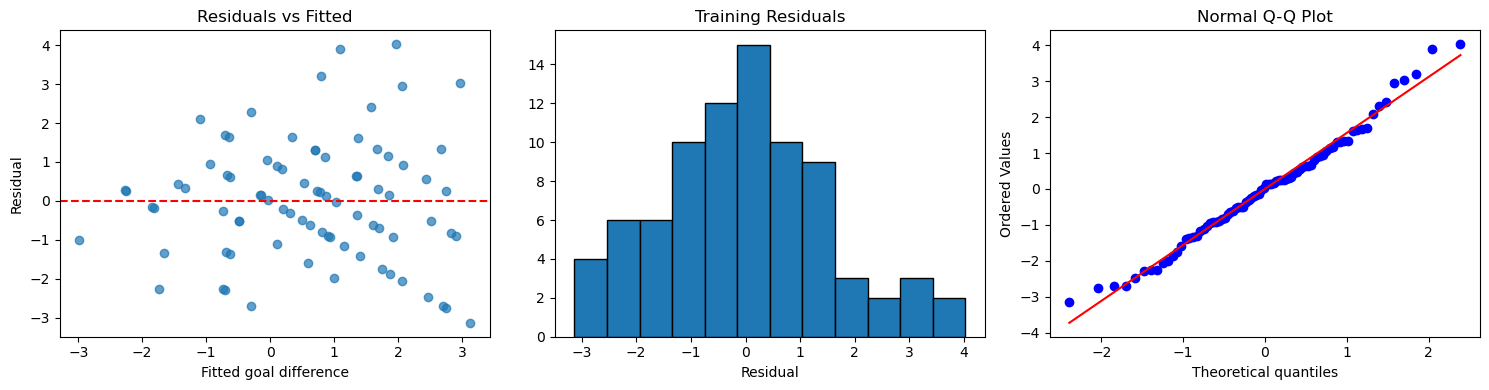

In [15]:
import matplotlib.pyplot as plt
from scipy import stats

training_predictions = model.predict(X_train)
training_residuals = y_train - training_predictions

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Residuals against fitted values
axes[0].scatter(training_predictions, training_residuals, alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Fitted")
axes[0].set_xlabel("Fitted goal difference")
axes[0].set_ylabel("Residual")

# Residual distribution
axes[1].hist(training_residuals, bins=12, edgecolor="black")
axes[1].set_title("Training Residuals")
axes[1].set_xlabel("Residual")

# Normal Q-Q plot
stats.probplot(training_residuals, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

In [16]:
test_results = test_data[
    ["Date", "home_team", "away_team", "goal_difference"]
].copy()

test_results["predicted_goal_difference"] = predictions
test_results["absolute_error"] = (
    test_results["goal_difference"]
    - test_results["predicted_goal_difference"]
).abs()

display(
    test_results
    .sort_values("absolute_error", ascending=False)
    .round(2)
)

,Date,home_team,away_team,goal_difference,predicted_goal_difference,absolute_error
93,2026-07-06,USA,Belgium,-3,0.58,3.58
88,2026-07-04,Canada,Morocco,-3,0.12,3.12
90,2026-07-05,Brazil,Norway,-1,1.30,2.30
102,2026-07-18,France,England,-2,-0.12,1.88
100,2026-07-14,France,Spain,-2,-0.14,1.86
91,2026-07-05,Mexico,England,-1,0.81,1.81
96,2026-07-09,France,Morocco,2,0.23,1.77
82,2026-07-02,Spain,Austria,3,1.41,1.59
99,2026-07-11,Argentina,Switzerland,2,0.43,1.57
84,2026-07-02,Switzerland,Algeria,2,0.61,1.39


In [17]:
coefficient_table = pd.DataFrame({
    "predictor": predictor_cols,
    "coefficient": model.coef_
})

display(
    coefficient_table
    .sort_values("coefficient", key=abs, ascending=False)
    .round(3)
)

print("Intercept:", round(model.intercept_, 3))

,predictor,coefficient
7,host_advantage,0.759
5,home_prior_goals_against_avg,-0.367
4,away_prior_goals_for_avg,0.170
6,away_prior_goals_against_avg,0.128
2,home_prior_matches,-0.117
1,away_fifa_rank,0.035
0,home_fifa_rank,-0.032
3,home_prior_goals_for_avg,-0.025


Intercept: 0.441


In [18]:
match_data.to_csv("world_cup_2026_enriched_matches.csv", index=False)
print("Shared match data saved:", match_data.shape)

Shared match data saved: (104, 16)
